<a href="https://colab.research.google.com/github/nisaerdemli/imageprocessing/blob/main/hafta5g%C3%B6rev5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Görev 5: 5 adet X-Ray görüntüsü işleniyor...



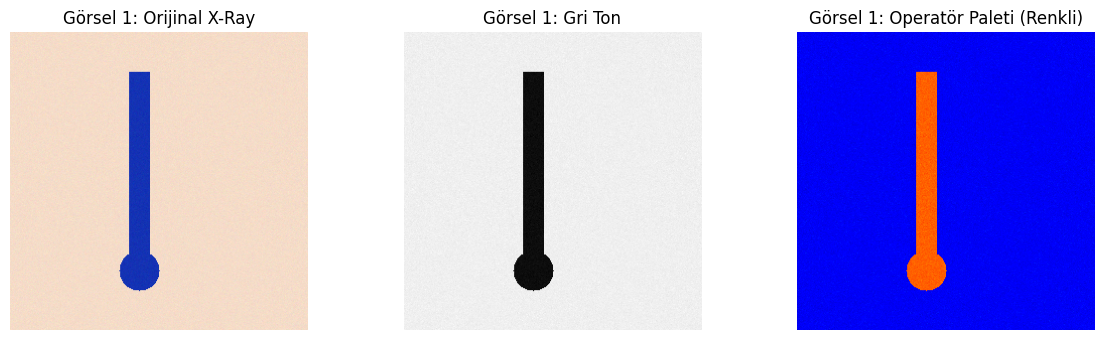

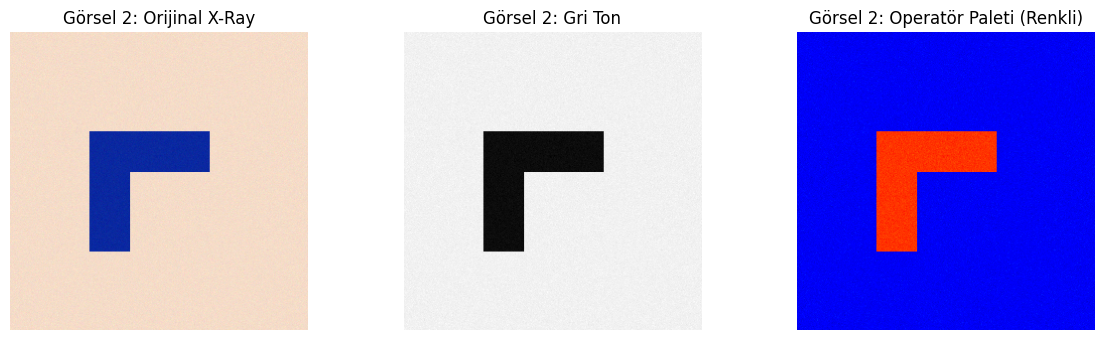

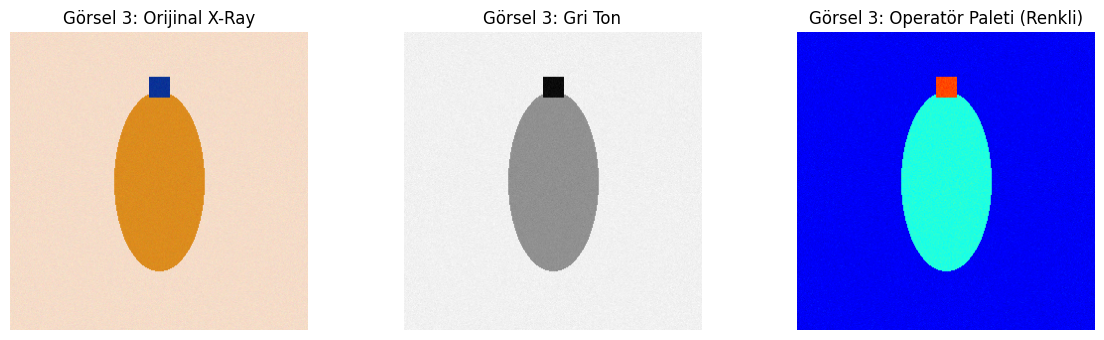

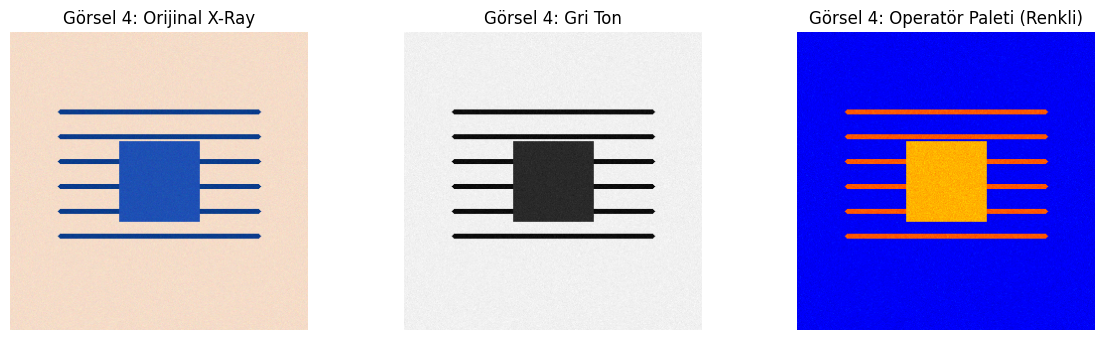

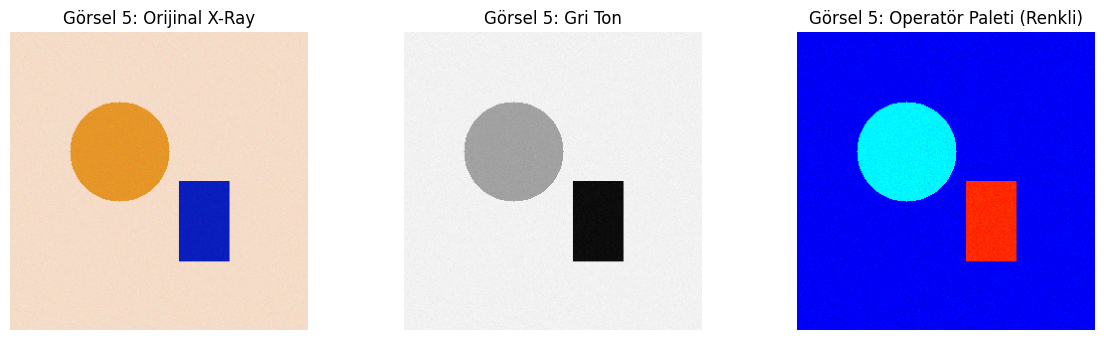


--- RAPOR CEVAPLARI (Ödev Metnine Eklenecek) ---
1. Neden Bu Renk Paleti (COLORMAP_JET) Seçildi?:
   - İnsan gözü 30-40 gri ton basamağını ayırt edebilirken, binlerce rengi ayırt edebilir.
   - Yüksek yoğunluklu ve tehdit oluşturan sert metaller sıcak renklere (kırmızı/sarı),
     düşük yoğunluklu organik malzemeler soğuk renklere (mavi) haritalanarak operatörün
     tehditleri anında fark etmesi sağlanmıştır.

2. Üretilen Resim ile Orijinal Renkli Resim Arasındaki Fark:
   - Orijinal çift enerjili (dual-energy) X-ray cihazları malzemelerin atomik numarasını (Zeff)
     doğrudan ölçüp renklendirir.
   - Biz gri ton üzerinden yalancı renklendirme yaptığımızda malzemenin kimyasal türü değil,
     sadece tek kanallı parlaklık/yoğunluk bilgisi renklendirildiği için ton farklılıkları oluşur.


In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# -------------------------------------------------------------
# 1. ADIM: 5 Adet Sentetik X-Ray Görüntüsü Üretici
# (Kaggle'dan resim indirme ihtiyacını ortadan kaldırır)
# -------------------------------------------------------------
def generate_synthetic_xray(index):
    # Arka plan: Bagaj boşluğu (hafif turuncu/açık sarı X-ray arka planı)
    h, w = 300, 300
    img = np.ones((h, w, 3), dtype=np.uint8) * 235
    img[:, :, 0] = 200  # Mavi
    img[:, :, 1] = 220  # Yeşil
    img[:, :, 2] = 245  # Kırmızı (Organik X-ray tonu)

    if index == 1:
        # Bıçak/Metal Tehdit: Yoğun mavi/koyu metalik bölge
        cv2.rectangle(img, (120, 40), (140, 240), (180, 50, 20), -1)
        cv2.circle(img, (130, 240), 20, (180, 50, 20), -1)
    elif index == 2:
        # Silah Şekli Benzetimi: Yüksek yoğunluklu metalik L şekli
        cv2.rectangle(img, (80, 100), (200, 140), (160, 40, 10), -1)
        cv2.rectangle(img, (80, 140), (120, 220), (160, 40, 10), -1)
    elif index == 3:
        # Şişe/Sıvı Tehdit: Organik sıvı ve cam çeper
        cv2.ellipse(img, (150, 150), (45, 90), 0, 0, 360, (30, 140, 220), -1)
        cv2.rectangle(img, (140, 45), (160, 65), (150, 50, 10), -1)
    elif index == 4:
        # Elektronik Devre / Kablo Yumağı: İnce yoğun teller
        for y in range(80, 220, 25):
            cv2.line(img, (50, y), (250, y), (140, 60, 10), 3)
        cv2.rectangle(img, (110, 110), (190, 190), (180, 80, 30), -1)
    elif index == 5:
        # Karışık Valiz: Giysi (turuncu) + Anahtarlık/Metal (koyu mavi)
        cv2.circle(img, (110, 120), 50, (40, 150, 230), -1)
        cv2.rectangle(img, (170, 150), (220, 230), (190, 30, 10), -1)

    # Gerçekçi X-ray görüntüsü için hafif gürültü ekle
    noise = np.random.normal(0, 4, img.shape).astype(np.int16)
    noisy_img = np.clip(img.astype(np.int16) + noise, 0, 255).astype(np.uint8)
    return noisy_img

# -------------------------------------------------------------
# 2. ADIM: Görev 5 - Griye Çevirme ve Operatör Renklendirmesi
# -------------------------------------------------------------
# Operatörler için standart havalimanı/tehdit paleti: cv2.COLORMAP_JET
colormap_choice = cv2.COLORMAP_JET

print("Görev 5: 5 adet X-Ray görüntüsü işleniyor...\n")

for i in range(1, 6):
    # 1. Renkli görüntüyü al
    orig_bgr = generate_synthetic_xray(i)

    # 2. Gri tona dönüştür
    gray_img = cv2.cvtColor(orig_bgr, cv2.COLOR_BGR2GRAY)

    # 3. Güvenlik operatörü için renklendir (Pseudocoloring)
    # X-ray tarayıcılarında yoğun/opak maddeler koyu çıkar, tehditlerin kırmızı parlaması
    # için parlaklığı ters çevirip (invert) renklendirmek operatör algısını artırır:
    inverted_gray = cv2.bitwise_not(gray_img)
    colored_img = cv2.applyColorMap(inverted_gray, colormap_choice)

    # 4. Görselleri Çizdir
    plt.figure(figsize=(12, 3.5))

    plt.subplot(1, 3, 1)
    plt.imshow(cv2.cvtColor(orig_bgr, cv2.COLOR_BGR2RGB))
    plt.title(f"Görsel {i}: Orijinal X-Ray")
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.imshow(gray_img, cmap='gray')
    plt.title(f"Görsel {i}: Gri Ton")
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.imshow(cv2.cvtColor(colored_img, cv2.COLOR_BGR2RGB))
    plt.title(f"Görsel {i}: Operatör Paleti (Renkli)")
    plt.axis('off')

    plt.tight_layout()
    plt.show()

print("\n--- RAPOR CEVAPLARI (Ödev Metnine Eklenecek) ---")
print("1. Neden Bu Renk Paleti (COLORMAP_JET) Seçildi?:")
print("   - İnsan gözü 30-40 gri ton basamağını ayırt edebilirken, binlerce rengi ayırt edebilir.")
print("   - Yüksek yoğunluklu ve tehdit oluşturan sert metaller sıcak renklere (kırmızı/sarı),")
print("     düşük yoğunluklu organik malzemeler soğuk renklere (mavi) haritalanarak operatörün")
print("     tehditleri anında fark etmesi sağlanmıştır.")
print()
print("2. Üretilen Resim ile Orijinal Renkli Resim Arasındaki Fark:")
print("   - Orijinal çift enerjili (dual-energy) X-ray cihazları malzemelerin atomik numarasını (Zeff)")
print("     doğrudan ölçüp renklendirir.")
print("   - Biz gri ton üzerinden yalancı renklendirme yaptığımızda malzemenin kimyasal türü değil,")
print("     sadece tek kanallı parlaklık/yoğunluk bilgisi renklendirildiği için ton farklılıkları oluşur.")